# Week 7: Bag of Words — Solution

Reference solutions for the Week 7 Bag-of-Visual-Words exercise. For some coding solutions you are provided with two versions that will execute and give the same results: vectorized implementation (using numpy package) and its alternative loop implementation (using standard python).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tavisualcomputing/viscomp2026/blob/main/Solutions/W7/W7_exercise_solution.ipynb)


In [1]:
# @title Quickstart for Google Colab
from pathlib import Path
if not Path("caltech-6").exists():
    !git clone --quiet --depth 1 https://github.com/tavisualcomputing/viscomp2026/
    %cd viscomp2026/Solutions/W7

## Setup

Install packages (needed on Colab), then import libraries. OpenCV provides SIFT;
scikit-learn provides k-means.


In [2]:
%pip install -q opencv-contrib-python-headless scikit-learn matplotlib pillow numpy

Note: you may need to restart the kernel to use updated packages.


## Dataset: Caltech-6 (Subset of Caltech-101)

Caltech-101 contains about 9 000 images from 101 object categories. Running SIFT and
k-means on the full set is slow on Colab, so we use a **small subset**: a few visually
distinct categories and a limited number of train/test images per category.

Default classes: `airplanes`, `Motorbikes`, `Faces`, `watch`, `car_side`, `Leopards`.

The helper `load_split` (in `dataset_utils.py`) loads grayscale images resized so the
long side is at most 300 pixels. 


In [3]:
%matplotlib inline
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

from dataset_utils import (
    DEFAULT_CATEGORIES,
    load_split,
    make_image_grid,
)

plt.rcParams["figure.dpi"] = 100
print("OpenCV", cv2.__version__, "| SIFT available:", hasattr(cv2, "SIFT_create"))
print("scikit-learn | KMeans available:", callable(KMeans))


OpenCV 5.0.0 | SIFT available: True
scikit-learn | KMeans available: True


Dataset root: /home/ankita/TA/viscomp2026/Solutions/W7/caltech-6
Classes (6): ['airplanes', 'Motorbikes', 'Faces', 'watch', 'car_side', 'Leopards']
Train images: 300 | Test images: 30


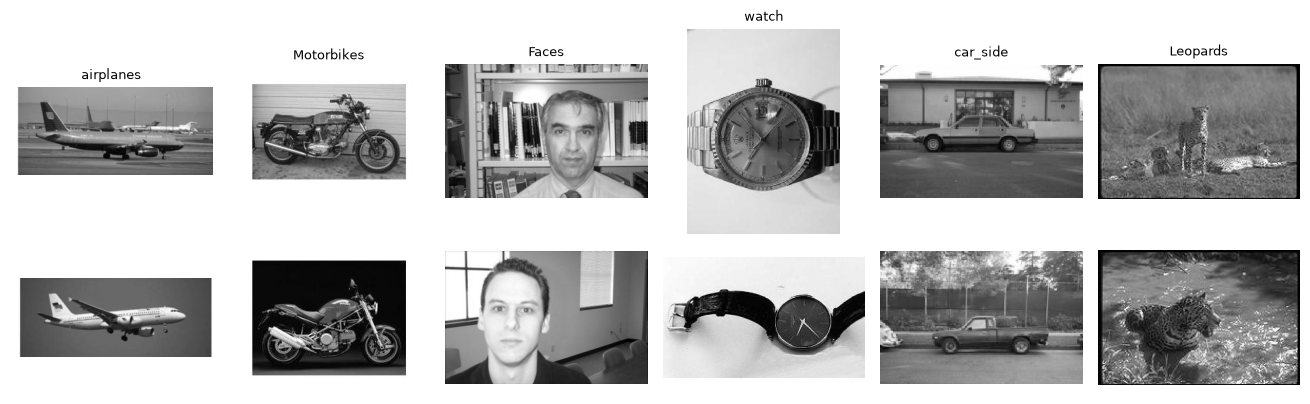

In [4]:
CATEGORIES = DEFAULT_CATEGORIES  # airplanes, Motorbikes, Faces, watch, car_side, Leopards
N_TRAIN = 50
N_TEST = 5
MAX_SIDE = 300
SEED = 0

data = load_split(
    categories=CATEGORIES,
    n_train=N_TRAIN,
    n_test=N_TEST,
    max_side=MAX_SIDE,
    seed=SEED,
)

class_names = data["class_names"]
train_images, test_images = data["train_images"], data["test_images"]
train_labels, test_labels = data["train_labels"], data["test_labels"]
train_paths, test_paths = data["train_paths"], data["test_paths"]

print(f"Dataset root: {data['root']}")
print(f"Classes ({len(class_names)}): {class_names}")
print(f"Train images: {len(train_images)} | Test images: {len(test_images)}")

fig, _ = make_image_grid(train_images, train_labels, class_names, cols=6, per_class=2)
plt.show()


# 1. Feature extraction using SIFT

Local descriptors are the “words” of our visual language. **SIFT** (Scale-Invariant
Feature Transform) detects keypoints that are stable under scale and rotation changes
and describes a neighbourhood around each keypoint with a **128-dimensional** vector.

We directly use the SIFT implementation provided in OpenCV: [documentation](https://docs.opencv.org/5.0/py_tutorials/py_features/py_sift_intro/py_sift_intro.html).


In [5]:
def extract_sift_descriptors(image_gray, nfeatures=800, rootsift=True):
    """Detect SIFT keypoints and compute 128-D descriptors for a grayscale image.
    Optionally applies RootSIFT (L1-normalize each descriptor, then square-root).

    Parameters:
        image_gray : np.ndarray, shape (H, W)
            Grayscale image (float in [0, 1] or uint8).
        nfeatures : int
            Maximum number of keypoints retained by OpenCV SIFT.
        rootsift : bool
            If True, apply RootSIFT normalization to the descriptors.

    Returns:
        keypoints : list of cv2.KeyPoint
            Detected keypoints (empty list if none found).
        descriptors : np.ndarray, shape (N, 128), dtype float32
            Descriptor matrix for the N keypoints, or None if none found.
    """
    if image_gray.dtype != np.uint8:
        image_gray = np.clip(image_gray * 255.0, 0, 255).astype(np.uint8)

    # Your lines here. Check the documentation linked above.
    # Use `cv2.SIFT_create` and provide nfeatures as the argument
    sift = cv2.SIFT_create(nfeatures=nfeatures)
    # Use `detectAndCompute` function of sift
    keypoints, descriptors = sift.detectAndCompute(image_gray, None)
    if descriptors is None:
        return [], None
    descriptors = descriptors.astype(np.float32)
        
    if rootsift:
        descriptors /= np.sum(descriptors, axis=1, keepdims=True) + 1e-12
        descriptors = np.sqrt(descriptors)
    return list(keypoints), descriptors

### Visualize SIFT keypoints

Run the next cell to check your extractor. You should see circles drawn on a few
training images. Typical images yield on the order of tens to a few hundred keypoints
with `nfeatures=800`.


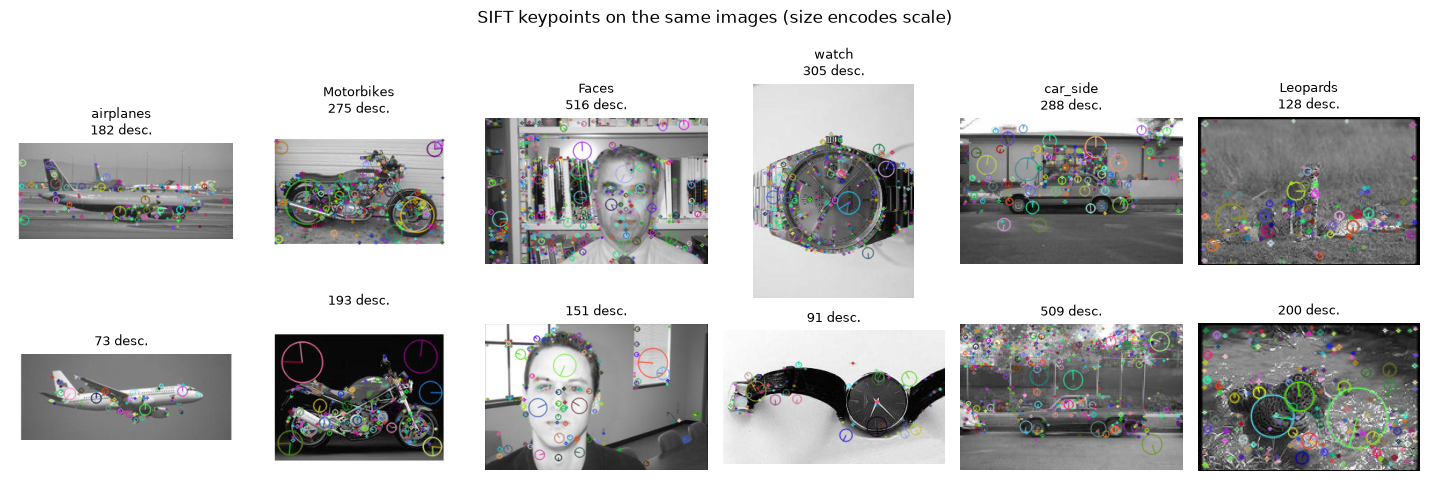

In [6]:
NFEATURES = 800
PER_CLASS = 2

labels_arr = np.asarray(train_labels)
classes = list(np.unique(labels_arr))
rows, cols = PER_CLASS, len(classes)
fig, axes = plt.subplots(rows, cols, figsize=(2.4 * cols, 2.6 * rows))
axes = np.atleast_2d(axes)

for col, cls in enumerate(classes):
    idxs = np.flatnonzero(labels_arr == cls)[:PER_CLASS]
    for row, img_idx in enumerate(idxs):
        img = train_images[int(img_idx)]
        kps, desc = extract_sift_descriptors(img, nfeatures=NFEATURES)
        img_u8 = np.clip(img * 255.0, 0, 255).astype(np.uint8)
        vis = cv2.drawKeypoints(
            img_u8,
            kps,
            None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
        )
        axes[row, col].imshow(vis, cmap="gray")
        n_desc = 0 if desc is None else len(desc)
        title = class_names[int(cls)] if row == 0 else ""
        axes[row, col].set_title(
            f"{title}\n{n_desc} desc." if title else f"{n_desc} desc.", fontsize=9
        )
        axes[row, col].set_axis_off()

fig.suptitle("SIFT keypoints on the same images (size encodes scale)")
fig.tight_layout()
plt.show()


In [7]:
print("Extracting SIFT on the training set...")
t0 = time.time()
train_keypoints, train_descriptors = [], []

for img in train_images:
    kps, desc = extract_sift_descriptors(img, nfeatures=NFEATURES)
    train_keypoints.append(kps)
    train_descriptors.append(desc)

print(f"Done in {time.time() - t0:.1f}s")
n_ok = sum(d is not None for d in train_descriptors)
n_desc = sum(0 if d is None else len(d) for d in train_descriptors)
print(f"Images with features: {n_ok}/{len(train_descriptors)}")
print(f"Total descriptors: {n_desc}")


Extracting SIFT on the training set...
Done in 1.0s
Images with features: 300/300
Total descriptors: 87256


# 2. K-means clustering for a visual vocabulary

Individual SIFT vectors are continuous and high-dimensional. To get discrete “words”,
we **cluster** a large pool of descriptors from the training images with **k-means**.
The $k$ cluster centres form the **codebook** (visual vocabulary).

Each centre is one visual word: a prototypical local appearance (e.g. a wheel edge,
an eye corner, a sky gradient).

We directly use the KMeans implementation provided by scikit-learn: [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

> NOTE: K-Means clustering on Colab takes ~4 mins. For quicker execution, change `max_descriptors` agrument to a smaller value (max_descriptors=40000).

In [8]:
def learn_codebook(descriptor_list, k=500, random_state=0, max_descriptors=100000):
    """Learn a visual vocabulary (codebook) by clustering SIFT descriptors with k-means.
    Descriptors from all images are stacked and optionally subsampled before clustering.

    Parameters:
        descriptor_list : list of np.ndarray
            Per-image descriptor arrays, each of shape (N_i, 128). Entries may be None
            or empty if an image had no features.
        k : int
            Vocabulary size (number of visual words / cluster centers).
        random_state : int
            Random seed for reproducibility (subsampling and k-means).
        max_descriptors : int
            Maximum number of descriptors used for clustering (random subsample if larger).

    Returns:
        codebook : np.ndarray, shape (k, 128), dtype float32
            Cluster centers; each row is one visual word.
    """
    valid = [d for d in descriptor_list if d is not None and len(d) > 0]
    if not valid:
        raise ValueError("No descriptors available to learn a codebook.")
    all_desc = np.vstack(valid).astype(np.float32)

    if all_desc.shape[0] > max_descriptors:
        rng = np.random.default_rng(random_state)
        idx = rng.choice(all_desc.shape[0], size=max_descriptors, replace=False)
        all_desc = all_desc[idx]

    # Your lines here. Check the documentation linked above.
    # Use `KMeans` from sklearn.cluster already imported.
    # Use `fit` method to compute k-means clustering.
    # Create the codebook using the `cluster_centers_` attribute.
    km = KMeans(n_clusters=k, random_state=random_state, n_init=3, max_iter=100)
    # km = KMeans(n_clusters=k) # Alternative: keep all parameters at default and just assign n_clusters=k
    km.fit(all_desc)
    codebook = km.cluster_centers_.astype(np.float32)
    return codebook


In [9]:
VOCAB_SIZE = 500

print(f"Learning codebook with k={VOCAB_SIZE}...")
t0 = time.time()
codebook = learn_codebook(train_descriptors, k=VOCAB_SIZE, random_state=SEED)
print(f"Codebook shape: {codebook.shape}  (took {time.time() - t0:.1f}s)")


Learning codebook with k=500...
Codebook shape: (500, 128)  (took 11.7s)


# 3. Build Bag-of-Words vectors

Given a codebook $K \in \mathbb{R}^{k \times 128}$, descriptors of an image $d \in \mathbb{R}^{N \times 128}$ is
**quantized** to the nearest-neighbour visual word (nearest centre in Euclidean distance).
Counting how often each word appears yields the **Term Frequency (TF)** vector:

$$
\boldsymbol{v}_d = [\text{TF}(w_{1,d}) \quad \text{TF}(w_{2,d}) \quad \cdots \quad \text{TF}(w_{k,d})]
$$

We L1-normalize so that $\sum_i \text{TF}(w_{i,d}) = 1$ (when the image has at least one descriptor).
This makes images with different numbers of keypoints comparable.

### TF–IDF weighting

Words that appear in almost every image are less informative (down-weights common terms).
We weight each term frequency by a heuristic $\text{IDF}(w_i)$ representing the **Inverse Document Frequency**:

$$
\text{IDF}(w_i) = \log \left\{ \frac{D}{\sum_{d'} \mathbf{1}[w_i \in d']} \right\}
$$

where $D$ is the total number of images (documents) and the denominator $\sum_{d'} \mathbf{1}[w_i \in d']$ counts the number of images containing word $w_i$.

Multiply each histogram element by its IDF weight and the resulting vector: 
$$
\boldsymbol{v}_d = [\text{TF}(w_{1,d}) \cdot \text{IDF}(w_1) \quad \text{TF}(w_{2,d}) \cdot \text{IDF}(w_2) \quad \cdots \quad \text{TF}(w_{k,d})\cdot \text{IDF}(w_k)]
$$
 
**L2-normalize** $\boldsymbol{v}_d$ and then the similarity between two images is a simple **dot product** (cosine similarity).


In [10]:
def quantize_descriptors_per_image(descriptors, codebook):
    """Assign each SIFT descriptor to its nearest visual word (nearest-neighbour quantization).
    Uses squared Euclidean distance between descriptors and codebook centers.

    Parameters:
        descriptors : np.ndarray, shape (N, 128)
            SIFT descriptors for one image (N keypoints).
        codebook : np.ndarray, shape (k, 128)
            Visual vocabulary; each row is a visual-word center.

    Returns:
        word_ids : np.ndarray, shape (N,), dtype int
            Visual-word index in {0, ..., k-1} for each descriptor.
    """
    desc = descriptors.astype(np.float32)
    code = codebook.astype(np.float32)

    # Your lines here.
    # Compute the Euclidean distance between each descriptor and each codebook center. (Hint: use broadcasting)

    # Vectorized implementation:
    diffs = desc[:, None, :] - code[None, :, :]   # (N, k, 128)
    dists = np.sum(diffs ** 2, axis=2)

    # Alternative loop implementation:
    # N, k = desc.shape[0], code.shape[0]
    # dists = np.zeros((N, k), dtype=np.float32)
    # for i in range(N):
    #     for j in range(k):
    #         dists[i, j] = np.sum((desc[i] - code[j]) ** 2)

    # Find the nearest codebook center for each descriptor  (Hint: use np.argmin)
    word_ids = np.argmin(dists, axis=1)
    return word_ids


def compute_bow_histogram_per_image(descriptors, codebook):
    """Build an L1-normalized bag-of-words histogram for one image.
    Quantizes descriptors to visual words, counts occurrences, and normalizes
    so the histogram sums to 1. Returns a zero vector if there are no descriptors.

    Parameters:
        descriptors : np.ndarray, shape (N, 128), or None
            SIFT descriptors for one image (may be None or empty).
        codebook : np.ndarray, shape (k, 128)
            Visual vocabulary; k is the number of visual words.

    Returns:
        hist : np.ndarray, shape (k,), dtype float64
            L1-normalized BoW histogram (term frequencies over visual words).
    """
    k = codebook.shape[0]
    hist = np.zeros(k, dtype=np.float64)
    if descriptors is None or len(descriptors) == 0:
        return hist
    # Your lines here.
    # Quantize the descriptors to visual words. (Hint: use the function you implemented above)
    # Count the occurrences of each visual word in the histogram and then normalize it so that it sums to 1. 
    words = quantize_descriptors_per_image(descriptors, codebook)
    for w in words:
        hist[w] += 1
    total = hist.sum()
    if total > 0:
        hist /= total
    return hist


In [11]:
def compute_idf(bow_matrix):
    """Compute inverse document frequency (IDF) for each visual word.
    For word j: idf[j] = log(n_images / df[j]), where df[j] is the number of
    images in which word j appears (BoW entry > 0).

    Parameters:
        bow_matrix : np.ndarray, shape (n_images, k)
            Rows are per-image L1-normalized BoW histograms (term frequencies).

    Returns:
        idf : np.ndarray, shape (k,), dtype float64
            IDF weight for each of the k visual words.
    """
    # Your lines here.
    # Compute df for each visual word by summing over the images where entry in bow_matrix is greater than 0.
    n_images,k = bow_matrix.shape

    #Vectorized implementation:
    df = np.sum(bow_matrix > 0, axis=0).astype(np.float64)
    
    # Alternative loop implementation:
    # df = np.zeros(k, dtype=np.float64)
    # for j in range(k):
    #     for i in range(n_images):
    #         if bow_matrix[i, j] > 0:
    #             df[j] += 1
    
    # Compute idf for each visual word as log(n_images / df).
    idf = np.log(n_images / df)
    return idf


def apply_tfidf(bow_matrix, idf):
    """Convert BoW histograms to TF-IDF vectors and L2-normalize each row.
    Multiplies each visual-word TF by its IDF, then divides each image vector
    by its L2 norm (with a small epsilon for empty rows).

    Parameters:
        bow_matrix : np.ndarray, shape (n_images, k)
            Per-image L1-normalized BoW histograms (term frequencies).
        idf : np.ndarray, shape (k,)
            Inverse document frequency weight per visual word.

    Returns:
        tfidf : np.ndarray, shape (n_images, k)
            L2-normalized TF-IDF matrix (one row per image).
    """
    # Your lines here.
    # Multiply each visual-word TF by its IDF.
    # Then L2-normalize each row (Hint: np.linalg.norm; guard against division by zero).

    # Vectorized implementation:
    weighted = bow_matrix * idf[None, :]
    norms = np.linalg.norm(weighted, axis=1, keepdims=True)
    norms = np.maximum(norms, 1e-12)
    tfidf = weighted / norms
    
    # Alternative loop implementation:
    # n_images, k = bow_matrix.shape
    # weighted = np.zeros_like(bow_matrix, dtype=np.float64)
    # for i in range(n_images):
    #     for j in range(k):
    #         weighted[i, j] = bow_matrix[i, j] * idf[j]
    # tfidf = np.zeros_like(weighted)
    # for i in range(n_images):
    #     norm = 0.0
    #     for j in range(k):
    #         norm += weighted[i, j] ** 2
    #     norm = max(norm ** 0.5, 1e-12)
    #     for j in range(k):
    #         tfidf[i, j] = weighted[i, j] / norm
    
    return tfidf


Building BOW histograms for training images...
train_bow shape: (300, 500)


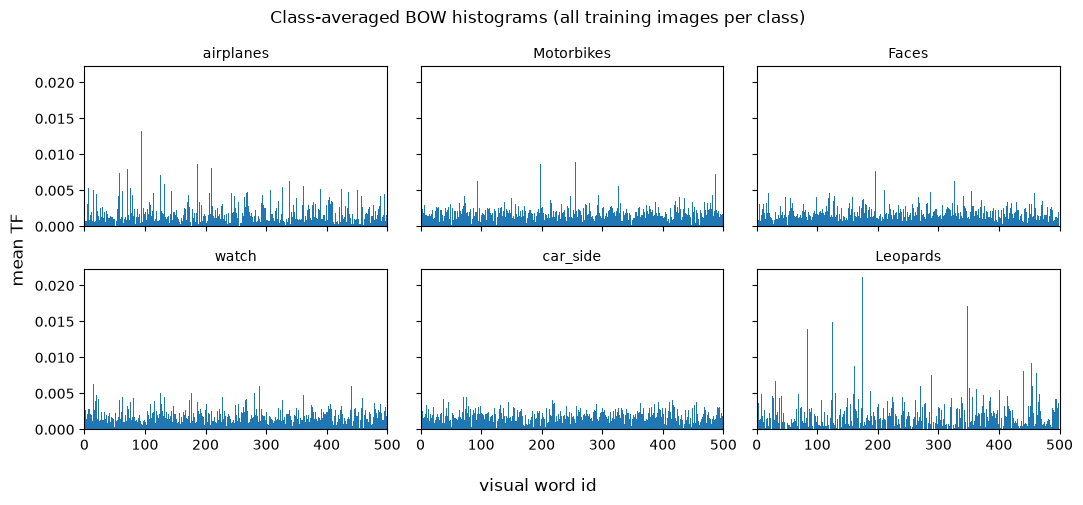

In [12]:
print("Building BOW histograms for training images...")
train_bow = np.stack(
    [compute_bow_histogram_per_image(d, codebook) for d in train_descriptors]
)
idf = compute_idf(train_bow)
train_tfidf = apply_tfidf(train_bow, idf)

print("train_bow shape:", train_bow.shape)

# Class-averaged BOW: mean histogram over all training images of each class.
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
for ax, cls in zip(axes.ravel(), range(len(class_names))):
    class_mean = train_bow[train_labels == cls].mean(axis=0)
    ax.bar(np.arange(VOCAB_SIZE), class_mean, width=1.0)
    ax.set_title(class_names[cls], fontsize=10)
    ax.set_xlim(0, VOCAB_SIZE)
fig.supxlabel("visual word id")
fig.supylabel("mean TF")
fig.suptitle("Class-averaged BOW histograms (all training images per class)")
fig.tight_layout()
plt.show()


# 4. Build an inverted index from the database

A dense loop “compare the query to every database image” works for a few hundred
images, but the classical retrieval trick is an **inverted index**, borrowed from
text search:

> For each visual word $w$, store the list of database images that contain $w$
> (and the TF–IDF weight of $w$ in that image).

At query time we only iterate over words that appear in the **query**. For each such
word we walk its posting list and accumulate a cosine-similarity score. Images that
share no visual words with the query stay at score 0 and are never visited.


In [13]:
def build_inverted_index(tfidf_matrix):
    """Build an inverted index from a TF-IDF matrix for sparse retrieval scoring.
    For each visual word, store the list of (image index, TF-IDF weight) pairs
    where that word has a non-zero weight. Words that never appear are omitted.

    Parameters:
        tfidf_matrix : np.ndarray, shape (n_images, k)
            L2-normalized TF-IDF matrix; row i is the representation of image i.

    Returns:
        inverted_index : dict[int, list[tuple[int, float]]]
            Maps visual-word id → list of (img_idx, weight) posting pairs.
            Only words with at least one non-zero entry are included.
    """
    n_images, k = tfidf_matrix.shape
    inverted_index = {word: [] for word in range(k)} #empty initialization

    # Your lines here.
    # Iterate over the images and the visual words.
    # If the weight is greater than 0, add the image index and weight to the posting list for the visual word.
    for img_idx in range(n_images):
        for word in range(k):
            weight = float(tfidf_matrix[img_idx, word])
            if weight > 0:
                inverted_index[word].append((img_idx, weight))

    # Dropping words that never appeared in any image
    inverted_index = {word: postings for word, postings in inverted_index.items() if postings}
    return inverted_index


def score_with_inverted_index(query_tfidf, inverted_index, n_images):
    """Score all database images against a query using the inverted index.
    For each visual word present in the query, add query_tfidf[word] * db_weight
    to each image that contains that word. With L2-normalized TF-IDF vectors,
    this is equivalent to sparse cosine similarity.

    Parameters:
        query_tfidf : np.ndarray, shape (k,)
            L2-normalized TF-IDF vector of the query image.
        inverted_index : dict[int, list[tuple[int, float]]]
            Maps visual-word id → list of (img_idx, weight) from the database.
        n_images : int
            Number of database images (length of the score vector).

    Returns:
        scores : np.ndarray, shape (n_images,), dtype float64
            Similarity score of the query to each database image.
    """
    scores = np.zeros(n_images, dtype=np.float64) #empty initialization
    # Iterating over the query TF-IDF vector.
    for word, q_val in enumerate(query_tfidf):
        if q_val == 0: # If the value is 0, continue to the next visual word.
            continue
        # Your lines here.
        # Iterate over the posting list of the visual word in the inverted index.
        # Add the query value times the weight to the score for the image index.
        for img_idx, weight in inverted_index.get(word, []):
            scores[img_idx] += q_val * weight
    return scores


In [14]:
inverted_index = build_inverted_index(train_tfidf)

# Quick sanity check: scoring a training image against the database should
# rank that same image first (self-similarity = 1 for L2-normalized TF-IDF).
q = train_tfidf[0]
scores = score_with_inverted_index(q, inverted_index, n_images=len(train_tfidf))
assert np.argmax(scores) == 0, "Self-retrieval failed — check inverted index / TF-IDF."
print(f"Self-retrieval OK (top score = {scores[0]:.3f})")

Self-retrieval OK (top score = 1.000)


### Query-by-example with the flat codebook

For each test image we extract SIFT, build a BoW histogram, apply the training IDF,
score the database with the inverted index, and predict the label by **majority vote**
among the top-$k$ retrieved training images.


In [15]:
def predict_label_knn(scores, db_labels, top_k=5):
    """Majority label among the top_k highest-scoring database images.

    If two classes share the same vote count, pick the one with the higher
    total similarity among those neighbors (then higher max score if still tied).
    """
    top = np.argsort(-scores)[:top_k]
    top_labels = db_labels[top]
    top_scores = scores[top]

    best_label, best_key = None, None  # key = (count, sum_score, max_score)
    for label in np.unique(top_labels):
        mask = top_labels == label
        key = (int(mask.sum()), float(top_scores[mask].sum()), float(top_scores[mask].max()))
        if best_key is None or key > best_key:
            best_key = key
            best_label = int(label)
    return best_label, top


def evaluate_retrieval(images, labels, codebook, idf, db_tfidf, inverted_index, db_labels, top_k=5):
    """Evaluate retrieval with top-k NN accuracy, precision, and recall.

    For each query, retrieved images with the same class label are relevant:
      precision = (# relevant in top-k) / (# returned)
      recall    = (# relevant in top-k) / (total # relevant in the database)
    Metrics are averaged over queries.
    """
    preds = []
    precisions = []
    recalls = []
    for img, label in zip(images, labels):
        _, desc = extract_sift_descriptors(img, nfeatures=NFEATURES)
        bow = compute_bow_histogram_per_image(desc, codebook)
        query_tfidf = apply_tfidf(bow[None, :], idf)[0]
        scores = score_with_inverted_index(query_tfidf, inverted_index, n_images=len(db_tfidf))
        pred, top = predict_label_knn(scores, db_labels, top_k=top_k)
        preds.append(pred)

        n_relevant_returned = int(np.sum(db_labels[top] == label))
        n_returned = len(top)
        n_relevant_total = int(np.sum(db_labels == label))
        precisions.append(n_relevant_returned / n_returned)
        recalls.append(n_relevant_returned / n_relevant_total)

    preds = np.asarray(preds)
    acc = np.mean(preds == labels)
    precision = float(np.mean(precisions))
    recall = float(np.mean(recalls))
    return acc, precision, recall, preds

In [16]:
TOP_K = 5
acc_flat, prec_flat, rec_flat, preds_flat = evaluate_retrieval(
    test_images, test_labels, codebook, idf, train_tfidf, inverted_index, train_labels, top_k=TOP_K
)
print(f"Flat codebook top-5 NN accuracy:  {acc_flat * 100:.1f}% (Max Accuracy Threshold = 100.0%)")
print(f"Flat codebook top-5 precision:   {prec_flat * 100:.1f}% (Max Precision Threshold = 100.0%)")
print(f"Flat codebook top-5 recall:      {rec_flat * 100:.1f}% (Max Recall Threshold = {TOP_K}/{N_TRAIN} * 100 = {TOP_K/N_TRAIN * 100:.1f}%)")

Flat codebook top-5 NN accuracy:  90.0% (Max Accuracy Threshold = 100.0%)
Flat codebook top-5 precision:   73.3% (Max Precision Threshold = 100.0%)
Flat codebook top-5 recall:      7.3% (Max Recall Threshold = 5/50 * 100 = 10.0%)


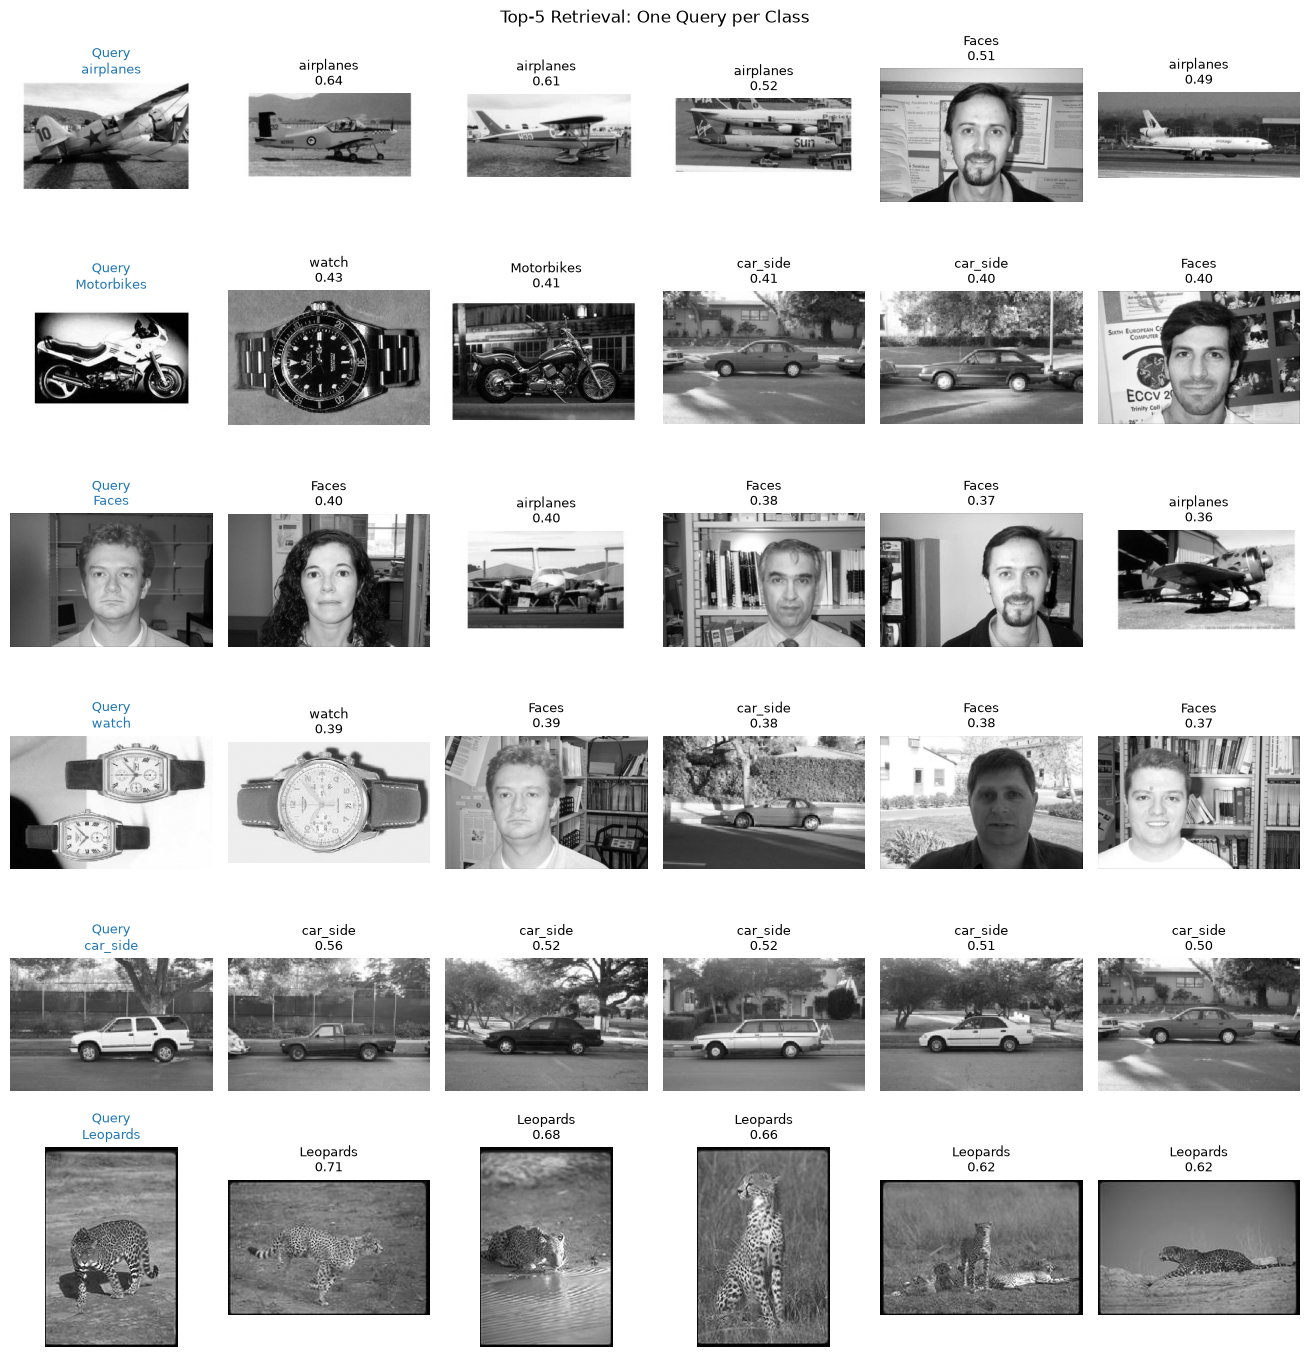

In [17]:
"""
One query per class. Test images are stored class-by-class, 
so the i-th test image of class n has index: i + (n * N_TEST), with 0 <= i < N_TEST.
"""
i = 0        # which test image within each class, change this to see different queries

n_classes = len(class_names)
fig, axes = plt.subplots(
    n_classes, 1 + TOP_K, figsize=(2.2 * (1 + TOP_K), 2.3 * n_classes)
)
axes = np.atleast_2d(axes)

for n, name in enumerate(class_names):
    query_idx = i + (n * N_TEST)
    q_img = test_images[query_idx]
    _, q_desc = extract_sift_descriptors(q_img, nfeatures=NFEATURES)
    q_bow = compute_bow_histogram_per_image(q_desc, codebook)
    q_tfidf = apply_tfidf(q_bow[None, :], idf)[0]
    q_scores = score_with_inverted_index(q_tfidf, inverted_index, n_images=len(train_tfidf))
    pred, top = predict_label_knn(q_scores, train_labels, top_k=TOP_K)

    axes[n, 0].imshow(q_img, cmap="gray")
    axes[n, 0].set_title(f"Query\n{name}", color="C0", fontsize=9)
    axes[n, 0].set_axis_off()
    for col, ti in enumerate(top):
        axes[n, 1 + col].imshow(train_images[ti], cmap="gray")
        axes[n, 1 + col].set_title(
            f"{class_names[train_labels[ti]]}\n{q_scores[ti]:.2f}", fontsize=9
        )
        axes[n, 1 + col].set_axis_off()
    # Mark the predicted class on the query title if wrong/right is useful:
    axes[n, 0].set_xlabel(
        f"Pred: {class_names[pred]}",
        color=("C2" if pred == test_labels[query_idx] else "C3"),
    )

fig.suptitle(f"Top-{TOP_K} Retrieval: One Query per Class")
fig.tight_layout()
plt.show()


If you finish early, try the following things to explore how the results change:

- Change `VOCAB_SIZE`, `NFEATURES`, or `N_TRAIN` and compare the accuracy.
- Turn off RootSIFT (`rootsift=False`) to check does this SIFT enhancement affect the accuracy.

# SAMPLE EXAM QUESTIONS 

![alt](Q1.png)

![alt](A1.png)

![alt](Q2.png)

![alt](A2.png)

![alt](Q3.png)

![alt](A3.png)

## References

- Sivic & Zisserman, *Video Google: A Text Retrieval Approach to Object Matching in Videos*, ICCV 2003.
- Lowe, *Distinctive Image Features from Scale-Invariant Keypoints*, IJCV 2004.
- Arandjelović & Zisserman, *Three Things Everyone Should Know to Improve Object Retrieval*, CVPR 2012 (RootSIFT).
